In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Su empresa prepara la oferta para un proyecto llave en mano. El equipo técnico ha estimado para cada actividad tres duraciones (optimista, más probable y pesimista, en semanas) y el cuadro de prelaciones, que se adjuntan. Hay que escribir en la oferta **el plazo de entrega comprometido**, y de él dependen penalizaciones y bonificaciones. Antes de cerrar la oferta recibe estos mensajes.

In [4]:
#| tbl-cap: "Cuadro de prelaciones y tres estimaciones de duración"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, optimista, mas_probable, pesimista
    ('A'     , '---'      , 4        , 5           , 6        ),
    ('B'     , '---'      , 1        , 2           , 9        ),
    ('C'     , '---'      , 1        , 1           , 7        ),
    ('D'     , 'A,B,C'    , 1        , 2           , 3        ),
    ('E'     , 'B'        , 1        , 1           , 1        ),
    ('F'     , 'D,E'      , 1        , 5           , 9        ),
    ('G'     , 'C'        , 4        , 7           , 10       ),
    ('H'     , 'G'        , 2        , 5           , 14       ),
    ('I'     , 'F'        , 2        , 4           , 6        ),
], columns=['activity', 'predecessor', 'optimista', 'mas_probable', 'pesimista']).set_index('activity')
datos_enunciado

,predecessor,optimista,mas_probable,pesimista
activity,,,,
A,---,4,5,6
B,---,1,2,9
C,---,1,1,7
D,"A,B,C",1,2,3
E,B,1,1,1
F,"D,E",1,5,9
G,C,4,7,10
H,G,2,5,14
I,F,2,4,6


> **De: Director comercial**
> El competidor va a ofertar 17 semanas. Con las estimaciones del equipo nos sale una duración de 16 semanas: propongo escribir **16 semanas** en la oferta, que es lo que dicen nuestros números y nos pone por delante. No veo por qué añadir colchón.

> **De: Jefe de producción**
> Las estimaciones son razonables salvo la de F: la duración pesimista (9) se queda corta, yo pondría al menos 11. Y recordad que las medias no se suman alegremente: si varias cosas van regular a la vez, el proyecto se va mucho más de lo que dice la ruta crítica.

> **De: Cliente**
> Las condiciones del contrato: penalización de **5 k€ por semana** de retraso sobre el plazo ofertado y bonificación de **2 k€ por semana** de adelanto. Valoraremos el plazo ofertado: cada semana por encima de 17 resta puntos en la adjudicación.

> **De: Asesoría jurídica**
> No podemos firmar un plazo que no estemos en condiciones de cumplir con alta probabilidad: pedimos que el plazo comprometido se cumpla **al menos en el 90 % de los escenarios**. Si el plazo es menor, que quede documentado quién asume el riesgo.

> **De: Dirección financiera**
> Ofertar más plazo tiene un coste comercial: estimamos que cada semana por encima de las 17 del competidor equivale a 3 k€ de descuento en precio para seguir siendo competitivos. Pero las penalizaciones se pagan en efectivo. Quiero el plazo que minimiza el coste esperado total.

Responda a las preguntas siguientes **antes** de decidir. En la penúltima se le pide la decisión y cómo la comunicaría a cada uno de los implicados (director comercial, jefe de producción, cliente, asesoría jurídica, dirección financiera).

In [5]:
pregunta_1 = "1. Con el método PERT (media y varianza de cada actividad a partir de las tres estimaciones) calcule la duración esperada, la desviación típica del camino crítico, la probabilidad de terminar en 16 semanas y el plazo que se cumpliría con el 90 % de probabilidad.  "
pregunta_2 = "2. Simule el proyecto por Monte Carlo (20000 réplicas, distribución PERT por actividad). Compare con lo anterior: probabilidad de terminar en 16 semanas, plazo al 90 % e índice de criticidad de cada actividad. ¿Por qué no coinciden? ¿Qué actividad no crítica merece vigilancia?  "
pregunta_3 = "3. Incorpore la observación del jefe de producción (pesimista de F = 11). ¿Cuánto cambian la media, la probabilidad y el plazo al 90 %?  "
pregunta_4 = "4. Con las réplicas de Monte Carlo, calcule para cada plazo candidato el coste esperado total: descuento comercial por semana ofertada por encima de 17, penalización esperada y bonificación esperada. ¿Qué plazo minimiza el coste esperado? ¿Cumple la condición de asesoría jurídica? Si no, ¿cuánto cuesta cumplirla?  "
pregunta_5 = "5. Decida el plazo que escribe en la oferta y redacte en tres o cuatro líneas la respuesta a cada implicado.  "
pregunta_6 = "6. ¿Qué lecciones generales saca sobre prometer plazos a partir de estimaciones (medias, colchones, actividades casi críticas, seguimiento)?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Con el método PERT (media y varianza de cada actividad a partir de las tres estimaciones) calcule la duración esperada, la desviación típica del camino crítico, la probabilidad de terminar en 16 semanas y el plazo que se cumpliría con el 90 % de probabilidad.  

2. Simule el proyecto por Monte Carlo (20000 réplicas, distribución PERT por actividad). Compare con lo anterior: probabilidad de terminar en 16 semanas, plazo al 90 % e índice de criticidad de cada actividad. ¿Por qué no coinciden? ¿Qué actividad no crítica merece vigilancia?  

3. Incorpore la observación del jefe de producción (pesimista de F = 11). ¿Cuánto cambian la media, la probabilidad y el plazo al 90 %?  

4. Con las réplicas de Monte Carlo, calcule para cada plazo candidato el coste esperado total: descuento comercial por semana ofertada por encima de 17, penalización esperada y bonificación esperada. ¿Qué plazo minimiza el coste esperado? ¿Cumple la condición de asesoría jurídica? Si no, ¿cuánto cuesta cumplirla?  

5. Decida el plazo que escribe en la oferta y redacte en tres o cuatro líneas la respuesta a cada implicado.  

6. ¿Qué lecciones generales saca sobre prometer plazos a partir de estimaciones (medias, colchones, actividades casi críticas, seguimiento)?  

# Resolución

In [6]:
def proyecto_de(predecesoras, duraciones, nombres):
    '''Tabla de datos y proyecto pmULE a partir de listas de predecesoras y duraciones.'''
    df = pd.DataFrame({'predecessor': list(predecesoras), 'duration': list(duraciones)}, index=list(nombres))
    df.index.name = 'activity'
    p = PredecessorTable.from_dataframe_of_strings(df, activity='activity', predecessor='predecessor').create_project()
    return df, p

def camino_critico(p, d):
    return '; '.join('–'.join(ruta) for ruta in p.critical_path(d).values())

def resumen_prob(p, d, sd, plazo):
    '''Duración media, desviación típica del camino crítico (la mayor si hay varios), P(T ≤ plazo) y retraso esperado.'''
    R = p.path_matrix(dummies=False)
    L = R @ d.reindex(R.columns)
    V = R @ (sd.reindex(R.columns).fillna(0) ** 2)
    T = float(L.max()); sigma = float(np.sqrt(V[L == T].max()))
    z = (plazo - T) / sigma
    retraso_esp = sigma * (norm.pdf(z) - z * norm.cdf(-z))      # E[máx(0, X − plazo)] con X ~ N(T, σ)
    return T, sigma, float(norm.cdf(z)), float(retraso_esp)

In [7]:
plazo_competidor, plazo_comercial, penalizacion, bonificacion, descuento = 17, 16, 5, 2, 3
datos_proyecto = datos_enunciado.copy()
datos_proyecto['duration'] = (datos_proyecto['optimista'] + 4 * datos_proyecto['mas_probable'] + datos_proyecto['pesimista']) / 6
datos_proyecto['varianza'] = ((datos_proyecto['pesimista'] - datos_proyecto['optimista']) / 6) ** 2
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
calendario = proyecto.calendar(datos_proyecto['duration'])

## Apartado 1

In [8]:
display(Markdown(pregunta_1))

1. Con el método PERT (media y varianza de cada actividad a partir de las tres estimaciones) calcule la duración esperada, la desviación típica del camino crítico, la probabilidad de terminar en 16 semanas y el plazo que se cumpliría con el 90 % de probabilidad.  

In [9]:
#| tbl-cap: "Media y varianza PERT de cada actividad; calendario"
#| label: tbl-pert
display(datos_proyecto[['optimista', 'mas_probable', 'pesimista', 'duration', 'varianza']].round(3))
calendario[['inicio_mas_temprano', 'fin_mas_temprano', 'H_total']]

,optimista,mas_probable,pesimista,duration,varianza
activity,,,,,
A,4,5,6,5.0,0.111
B,1,2,9,3.0,1.778
C,1,1,7,2.0,1.000
D,1,2,3,2.0,0.111
E,1,1,1,1.0,0.000
F,1,5,9,5.0,1.778
G,4,7,10,7.0,1.000
H,2,5,14,6.0,4.000
I,2,4,6,4.0,0.444


,inicio_mas_temprano,fin_mas_temprano,H_total
activity,,,
A,0.0,5.0,0.0
B,0.0,3.0,2.0
C,0.0,2.0,1.0
D,5.0,7.0,0.0
E,3.0,4.0,3.0
F,7.0,12.0,0.0
G,2.0,9.0,1.0
H,9.0,15.0,1.0
I,12.0,16.0,0.0


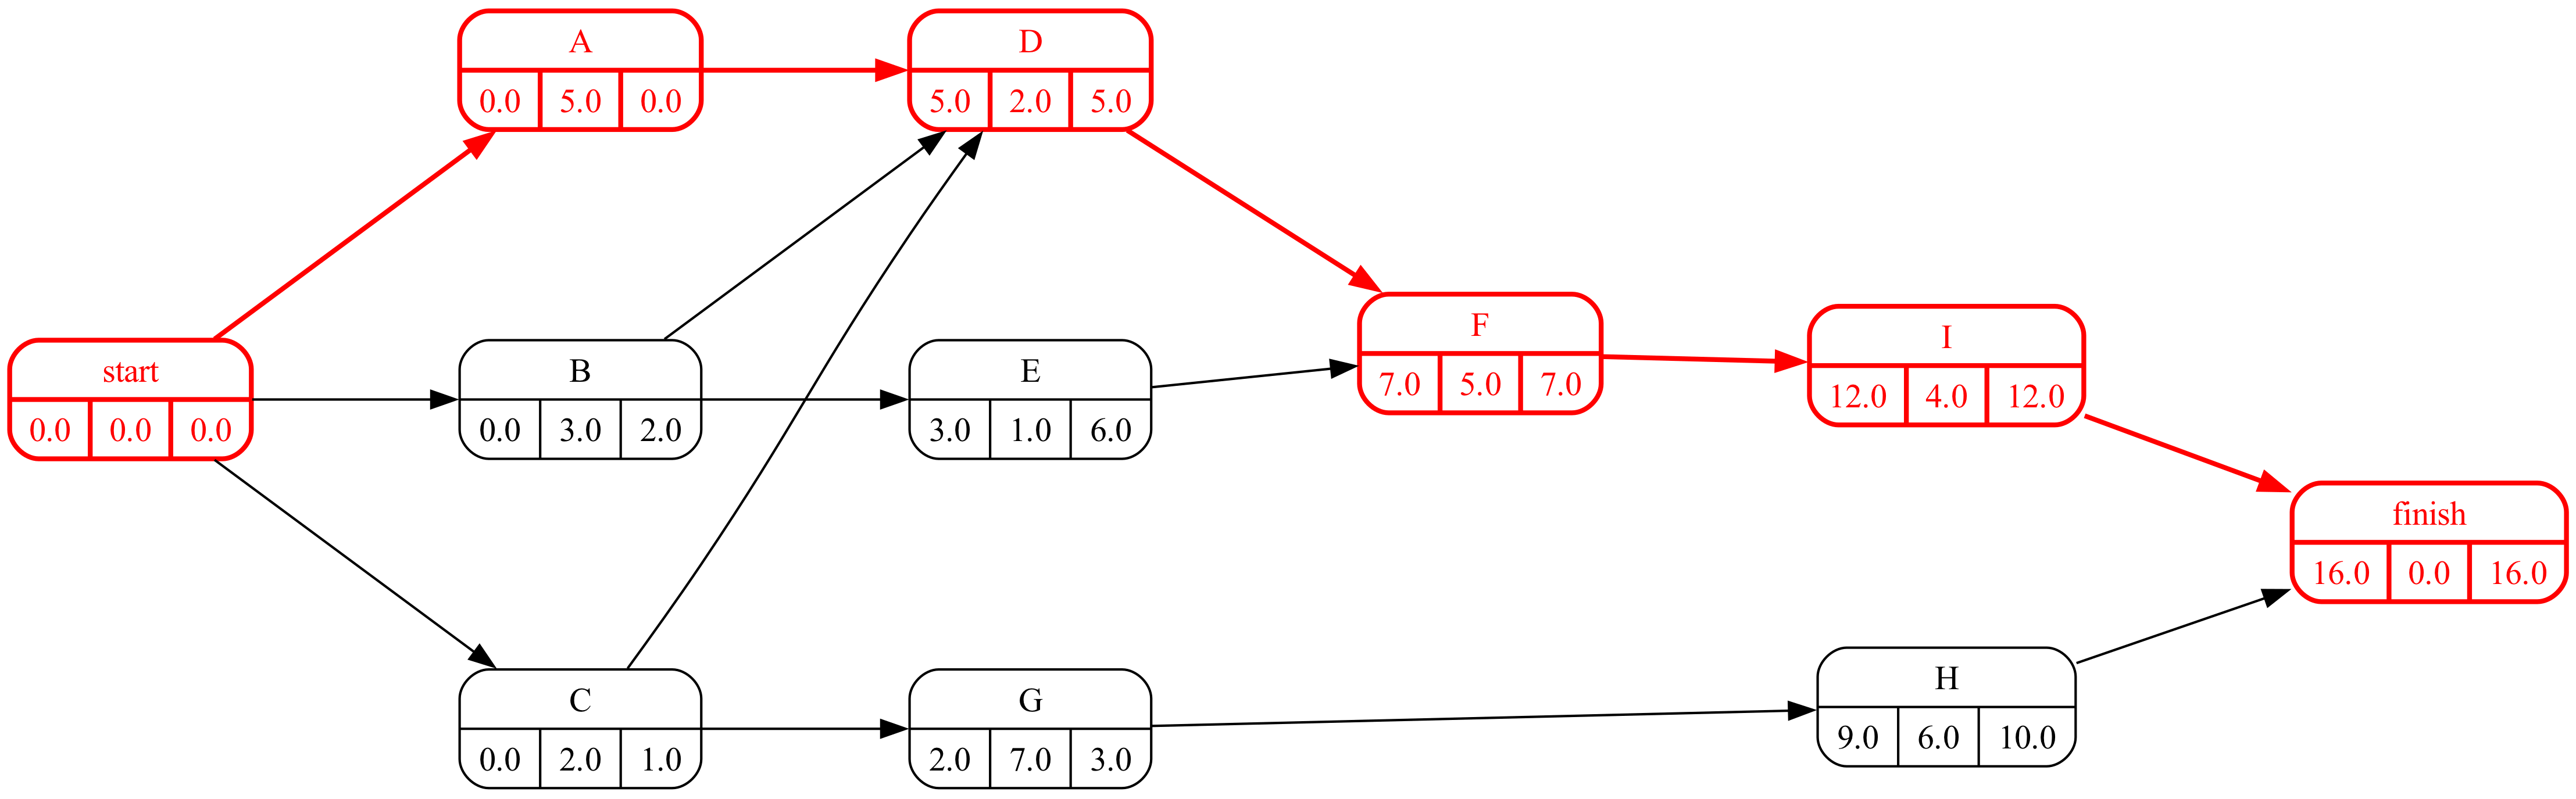

In [10]:
#| fig-cap: "Grafo Roy con las duraciones medias y el camino crítico"
#| label: fig-pert
proyecto.roy(durations=datos_proyecto['duration'], ranksep=1.2, nodesep=1.2)

Cálculo de los tiempos mínimos y máximos de los nodos del grafo Roy paso a paso (avance con los botones):

In [ ]:
proyecto.display_roy_pasos(datos_proyecto['duration'])

In [11]:
T_media = float(proyecto.duration(datos_proyecto['duration']))
sigma, varianzas_caminos = proyecto.standard_deviation(datos_proyecto['duration'], datos_proyecto['varianza'].to_dict())
display(varianzas_caminos)
p_pert = norm.cdf((plazo_comercial - T_media) / sigma)
plazo90_pert = T_media + norm.ppf(0.9) * sigma
Markdown(f'''Duración esperada {T_media:.1f} semanas, camino crítico {camino_critico(proyecto, datos_proyecto["duration"])}, σ = {sigma:.2f}. P(T ≤ {T_media:.0f}) = {p_pert:.2f} (la media se cumple la mitad de las veces); plazo al 90 %: {T_media:.1f} + 1.28 × {sigma:.2f} = **{plazo90_pert:.1f} semanas**.''')

,Activities,Variance
Route_1,"A, D, F, I",2.44


Duración esperada 16.0 semanas, camino crítico A–D–F–I, σ = 1.56. P(T ≤ 16) = 0.50 (la media se cumple la mitad de las veces); plazo al 90 %: 16.0 + 1.28 × 1.56 = **18.0 semanas**.

## Apartado 2

In [12]:
display(Markdown(pregunta_2))

2. Simule el proyecto por Monte Carlo (20000 réplicas, distribución PERT por actividad). Compare con lo anterior: probabilidad de terminar en 16 semanas, plazo al 90 % e índice de criticidad de cada actividad. ¿Por qué no coinciden? ¿Qué actividad no crítica merece vigilancia?  

In [13]:
resultado = proyecto.monte_carlo({act: ('pert', int(fila['optimista']), int(fila['mas_probable']), int(fila['pesimista'])) for act, fila in datos_proyecto.iterrows()},
                                 n_samples=20000, seed=2024)
tau = resultado.tau_samples
display(resultado.summary().round(2))
p_mc = float((tau <= plazo_comercial).mean()); plazo90_mc = float(np.quantile(tau, 0.9))
criticidad = (resultado.sensitivity_mean * 100).round(1)
display(pd.DataFrame({'criticidad (%)': criticidad, 'holgura total': calendario['H_total']}).T)
Markdown(f'''Monte Carlo: media {tau.mean():.2f}, desviación típica {tau.std():.2f}; P(T ≤ {plazo_comercial}) = **{p_mc:.2f}** (PERT decía {p_pert:.2f}); plazo al 90 %: **{plazo90_mc:.1f}** semanas (PERT decía {plazo90_pert:.1f}).''')

,mean,std,q05,q50,q95,min,max
τ,16.76,1.57,14.3,16.71,19.43,11.01,24.52


,A,B,C,D,E,F,G,H,I
criticidad (%),58.6,4.8,36.5,63.5,0.0,63.5,36.5,36.5,63.5
holgura total,0.0,2.0,1.0,0.0,3.0,0.0,1.0,1.0,0.0


Monte Carlo: media 16.76, desviación típica 1.57; P(T ≤ 16) = **0.32** (PERT decía 0.50); plazo al 90 %: **18.8** semanas (PERT decía 18.0).

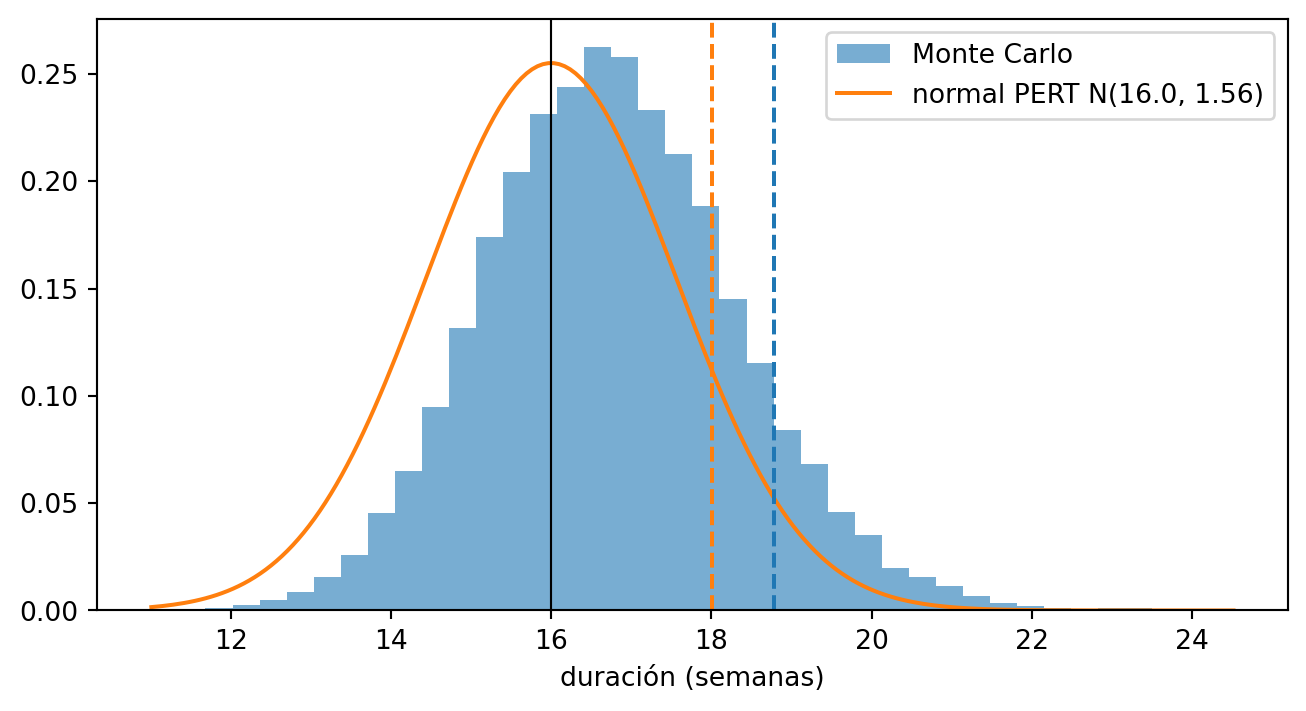

In [14]:
#| fig-cap: "Distribución simulada de la duración y los dos plazos al 90 %"
#| label: fig-histograma
from matplotlib import pyplot as plt
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(tau, bins=40, density=True, alpha=0.6, label='Monte Carlo')
xs = np.linspace(tau.min(), tau.max(), 200); ax.plot(xs, norm.pdf(xs, T_media, sigma), label=f'normal PERT N({T_media:.1f}, {sigma:.2f})')
ax.axvline(plazo90_pert, ls='--', color='C1'); ax.axvline(plazo90_mc, ls='--', color='C0'); ax.axvline(T_media, color='k', lw=0.8)
ax.set_xlabel('duración (semanas)'); ax.legend();

La media PERT (16) subestima la duración y la normal del camino crítico subestima la cola derecha: en las réplicas hay otras rutas (la segunda dura 15 en media) que en bastantes escenarios se convierten en la más larga. Es el *sesgo de fusión* (merge bias): el máximo de varias variables aleatorias tiene media mayor que el mayor de sus medias. Por eso P(T ≤ 16) baja del 0.50 al 0.32 y el plazo al 90 % sube de 18.0 a 18.8. La actividad no crítica con más criticidad es **C** (37% de las réplicas en la ruta más larga, holgura 1): el análisis determinista la da por holgada y conviene vigilarla como si fuera crítica.

## Apartado 3

In [15]:
display(Markdown(pregunta_3))

3. Incorpore la observación del jefe de producción (pesimista de F = 11). ¿Cuánto cambian la media, la probabilidad y el plazo al 90 %?  

In [16]:
datos_prod = datos_proyecto.copy(); datos_prod.loc['F', 'pesimista'] += 2
datos_prod['duration'] = (datos_prod['optimista'] + 4 * datos_prod['mas_probable'] + datos_prod['pesimista']) / 6
datos_prod['varianza'] = ((datos_prod['pesimista'] - datos_prod['optimista']) / 6) ** 2
T_prod = float(proyecto.duration(datos_prod['duration']))
sigma_prod, _ = proyecto.standard_deviation(datos_prod['duration'], datos_prod['varianza'].to_dict())
resultado_prod = proyecto.monte_carlo({act: ('pert', int(fila['optimista']), int(fila['mas_probable']), int(fila['pesimista'])) for act, fila in datos_prod.iterrows()}, n_samples=20000, seed=2024)
tau_prod = resultado_prod.tau_samples
pd.DataFrame({'estimaciones del equipo': [T_media, sigma, p_pert, plazo90_pert, p_mc, plazo90_mc],
              'pesimista de F + 2': [T_prod, sigma_prod, norm.cdf((plazo_comercial - T_prod) / sigma_prod), T_prod + norm.ppf(0.9) * sigma_prod,
                                        float((tau_prod <= plazo_comercial).mean()), float(np.quantile(tau_prod, 0.9))]},
             index=['media PERT', 'σ PERT', f'P(T ≤ {plazo_comercial}) PERT', 'plazo 90 % PERT', f'P(T ≤ {plazo_comercial}) MC', 'plazo 90 % MC']).round(2)

,estimaciones del equipo,pesimista de F + 2
media PERT,16.00,16.33
σ PERT,1.56,1.86
P(T ≤ 16) PERT,0.50,0.43
plazo 90 % PERT,18.00,18.71
P(T ≤ 16) MC,0.32,0.28
plazo 90 % MC,18.78,19.25


Añadir dos semanas a la estimación pesimista de F sube su media en 0.33 semanas y su varianza; la duración esperada pasa a 16.33 y el plazo al 90 % por Monte Carlo a 19.2. El efecto es moderado pero va en la misma dirección: cuanto más incierta la actividad crítica, más colchón hace falta para la misma probabilidad. Y es información que el equipo de producción tenía y la oferta no.

## Apartado 4

In [17]:
display(Markdown(pregunta_4))

4. Con las réplicas de Monte Carlo, calcule para cada plazo candidato el coste esperado total: descuento comercial por semana ofertada por encima de 17, penalización esperada y bonificación esperada. ¿Qué plazo minimiza el coste esperado? ¿Cumple la condición de asesoría jurídica? Si no, ¿cuánto cuesta cumplirla?  

In [18]:
#| tbl-cap: "Coste esperado (k€) según el plazo ofertado, con las réplicas de Monte Carlo"
#| label: tbl-plazos
candidatos = range(int(T_media) - 1, int(np.ceil(np.quantile(tau, 0.97))) + 2)
filas = []
for Dp in candidatos:
    pen_esp = penalizacion * float(np.maximum(tau - Dp, 0).mean())
    bon_esp = bonificacion * float(np.maximum(Dp - tau, 0).mean())
    com = descuento * max(0, Dp - plazo_competidor)
    filas.append({'plazo ofertado': Dp, 'P(cumplir)': float((tau <= Dp).mean()), 'penalización esperada': pen_esp,
                  'bonificación esperada': bon_esp, 'descuento comercial': com, 'coste esperado total': com + pen_esp - bon_esp})
plazos = pd.DataFrame(filas).set_index('plazo ofertado')
display(plazos.round(2))
D_opt = int(plazos['coste esperado total'].idxmin()); D_legal = int(np.ceil(plazo90_mc))
Markdown(f'''El plazo que minimiza el coste esperado es **{D_opt} semanas** (P(cumplir) = {plazos.loc[D_opt, "P(cumplir)"]:.2f}); el que exige asesoría jurídica (90 %) es **{D_legal}** semanas, con coste esperado {plazos.loc[D_legal, "coste esperado total"]:.1f} k€ frente a {plazos.loc[D_opt, "coste esperado total"]:.1f}: cumplir la condición cuesta {plazos.loc[D_legal, "coste esperado total"] - plazos.loc[D_opt, "coste esperado total"]:.1f} k€ esperados.''')

,P(cumplir),penalización esperada,bonificación esperada,descuento comercial,coste esperado total
plazo ofertado,,,,,
15,0.12,9.26,0.18,0,9.08
16,0.32,5.34,0.61,0,4.73
17,0.58,2.57,1.50,0,1.07
18,0.79,1.02,2.88,3,1.14
19,0.92,0.34,4.61,6,1.73
20,0.97,0.10,6.51,9,2.59
21,0.99,0.03,8.48,12,3.54


El plazo que minimiza el coste esperado es **17 semanas** (P(cumplir) = 0.58); el que exige asesoría jurídica (90 %) es **19** semanas, con coste esperado 1.7 k€ frente a 1.1: cumplir la condición cuesta 0.7 k€ esperados.

Prometer 16 semanas (lo que pide el director comercial) tiene un coste esperado de 4.7 k€ y se cumple el 32% de las veces; el óptimo económico es 17 (1.1 k€, P = 0.58) y el plazo «jurídico» 19 (1.7 k€). La penalización esperada decrece con el plazo ofertado y el descuento comercial crece 3 k€ por semana: el óptimo está donde la penalización marginal evitada iguala el descuento marginal. La condición del 90 % es una preferencia por el riesgo, no un óptimo en media: su coste es la diferencia entre las dos filas, y conviene que quien la impone lo sepa.

## Apartado 5

In [19]:
display(Markdown(pregunta_5))

5. Decida el plazo que escribe en la oferta y redacte en tres o cuatro líneas la respuesta a cada implicado.  

Una decisión defendible: ofertar **19 semanas**, el plazo al 90 %: la diferencia de coste esperado con el óptimo (0.7 k€) es pequeña frente al riesgo reputacional de incumplir, y evita la discusión interna. En ningún caso 16: es la media, y la media se incumple la mitad de las veces en el mejor de los casos (aquí, el 68%). Mensajes:

- *Director comercial:* «16 semanas es la duración media, no un plazo: se incumpliría el 68% de las veces y cada semana cuesta 5 k€. Propongo 19; el coste esperado total es 1.7 k€ frente a 4.7 con 16.»
- *Jefe de producción:* «Incorporada tu estimación de F; sube el plazo al 90 % en 0.5 semanas. Durante la ejecución vigilaremos F y también C, que aparece crítica en el 37% de los escenarios.»
- *Cliente:* «Plazo ofertado: 19 semanas, con las penalizaciones y bonificaciones acordadas.»
- *Asesoría jurídica:* «El plazo ofertado se cumple en el 92% de los escenarios simulados.»
- *Dirección financiera:* «Coste esperado por plazo adjunto; el mínimo es 17 semanas (1.1 k€) y el plazo al 90 % cuesta 0.7 k€ más en media. La propuesta es 19.»

## Apartado 6

In [20]:
display(Markdown(pregunta_6))

6. ¿Qué lecciones generales saca sobre prometer plazos a partir de estimaciones (medias, colchones, actividades casi críticas, seguimiento)?  

- La duración media del camino crítico no es un plazo: se cumple la mitad de las veces como mucho, y menos cuando hay rutas casi críticas (sesgo de fusión). Un plazo se promete con una probabilidad explícita.
- El colchón tiene un precio (descuento, competitividad) y la falta de colchón también (penalización esperada); la decisión es económica y se puede calcular con las réplicas.
- Las actividades casi críticas con mucha varianza son las que convierten el plan en papel mojado: el índice de criticidad dice cuáles vigilar, cosa que el análisis determinista no puede.
- La información del jefe de producción debía haber entrado en las estimaciones antes de calcular nada: estimar es un proceso de equipo, no una hoja que rellena uno.